# 🏪 Fase 2 — Segmentación RFM con K-Medoids
## Prueba Técnica Pragma · Analítica de Banca Digital

**Objetivo**: Segmentar los **3 015 comercios** activos en los últimos 6 meses usando **K-Medoids (PAM)**
para identificar grupos accionables y compararlo cuantitativamente contra K-Means.

### Ventajas de K-Medoids sobre K-Means
| Criterio | K-Means | K-Medoids |
|----------|---------|-----------|
| Resistencia a outliers | ❌ Media (centroide puede salirse) | ✅ Alta (medoide es un punto real) |
| Interpretabilidad | Centroide matemático | Comercio real representativo |
| Auditoría | Difícil | Fácil (ID real del comercio) |
| Asignación 100% | ✅ | ✅ |

### Matriz de Artefactos
| Artefacto | Ruta |
|-----------|------|
| Dataset final | `data/processed/comercios_final_k_medoids.csv` |
| Perfiles segmentos | `data/processed/perfiles_segmentos_k_medoids.csv` |
| Modelo K-Medoids | `data/processed/model_k_medoids.pkl` |
| Scaler | `data/processed/scaler_k_medoids.pkl` |
| Metadata | `data/processed/metadata_segmentation_k_medoids.json` |
| Plots | `data/processed/plots/kmedoids_*.png` |

> ⚠️ **Ejecución iterativa recomendada**: correr celda a celda y revisar cada output antes de avanzar.

In [16]:
from __future__ import annotations
import json
import pickle
import warnings
from datetime import datetime
from pathlib import Path
from typing import Optional

import joblib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats as sp_stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    silhouette_score,
    silhouette_samples,
)
from sklearn.preprocessing import RobustScaler, StandardScaler

# K-Medoids con fallback
try:
    from sklearn_extra.cluster import KMedoids
    KMEDOIDS_BACKEND = "sklearn_extra"
except ImportError:
    try:
        from pyclustering.cluster.kmedoids import kmedoids as PyKMedoids
        KMEDOIDS_BACKEND = "pyclustering"
    except ImportError:
        KMEDOIDS_BACKEND = "none"
        print("⚠️  Ningún backend de K-Medoids disponible. Instalar sklearn-extra o pyclustering.")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ── Parámetros Globales ──────────────────────────────────────────────
SUFFIX         = "_k_medoids"
LOG_TRANSFORM  = True
SCALE_METHOD   = "standard"   # "standard" | "robust"
K_RANGE        = range(2, 9)  # K = 2..8
RANDOM_STATE   = 42
SKEW_THRESHOLD = 1.0
CORR_THRESHOLD = 0.85

COL_MAP = {
    "recencia_dias"             : "recency_days",
    "frecuencia"                : "frequency",
    "monetary"                  : "monetary",
    "ticket_promedio"           : "ticket_avg",
    "comision_generada"         : "commission",
    "n_terminals"               : "n_terminals",
    "actividad_mensual_promedio": "monthly_activity",
    "meses_activos"             : "active_months",
}

# Feature sets
FEATURE_SET_A = ["recency_days", "frequency", "monetary"]
FEATURE_SET_B = ["recency_days", "frequency", "monetary", "ticket_avg", "n_terminals"]

ACTIVE_FEATURE_SET = FEATURE_SET_A

# Rutas
BASE_DIR  = Path("..")
DATA_DIR  = BASE_DIR / "data" / "processed"
PLOTS_DIR = DATA_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Tema visual
sns.set_theme(style="whitegrid", palette="tab10", font_scale=1.1)
PALETTE = sns.color_palette("tab10")

_feat_label = "A (RFM Clásico)" if ACTIVE_FEATURE_SET == FEATURE_SET_A else "B (RFM Extendido)"
print("✅ Configuración cargada")
print(f"   SUFFIX          : {SUFFIX}")
print(f"   DATA_DIR        : {DATA_DIR.resolve()}")
print(f"   PLOTS_DIR       : {PLOTS_DIR.resolve()}")
print(f"   KMEDOIDS_BACKEND: {KMEDOIDS_BACKEND}")
print(f"   Feature Set     : {_feat_label}")
print(f"   K_RANGE         : {list(K_RANGE)}")

✅ Configuración cargada
   SUFFIX          : _k_medoids
   DATA_DIR        : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed
   PLOTS_DIR       : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed\plots
   KMEDOIDS_BACKEND: pyclustering
   Feature Set     : A (RFM Clásico)
   K_RANGE         : [2, 3, 4, 5, 6, 7, 8]


## 1. Carga y Validación de Datos

Cargamos `comercios_segmented_prep.csv` producido por la **Fase 1 (ETL)**.
Contiene métricas RFM calculadas a nivel de comercio para los últimos 6 meses (corte: **2021-05-01**).

| Variable | Descripción | Transformación COL_MAP |
|----------|-------------|------------------------|
| `recencia_dias` → `recency_days` | Días desde última transacción | Renombrar |
| `frecuencia` → `frequency` | N° transacciones en período | Renombrar |
| `monetary` | Monto ventas acumulado | Ya canónico |
| `ticket_promedio` → `ticket_avg` | Ticket promedio por transacción | Renombrar |
| `comision_generada` → `commission` | Comisión generada al banco | Renombrar |
| `n_terminals` | Terminales asociadas | Ya canónico |
| `meses_activos` → `active_months` | Meses con al menos 1 transacción | Renombrar |

In [17]:
def load_processed_data(filepath: Path) -> pd.DataFrame:
    """Carga y valida el dataset procesado de comercios.

    Args:
        filepath: Ruta al archivo CSV procesado.

    Returns:
        DataFrame con columnas renombradas al esquema canónico.

    Raises:
        FileNotFoundError: Si el archivo no existe.
        ValueError: Si faltan columnas requeridas.
    """
    if not filepath.exists():
        raise FileNotFoundError(f"Archivo no encontrado: {filepath}")

    df = pd.read_csv(filepath)
    df = df.rename(columns=COL_MAP)

    required = ["id_comercio", "recency_days", "frequency", "monetary",
                "ticket_avg", "commission", "n_terminals", "active_months"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Columnas faltantes: {missing}")

    null_counts = df[required].isnull().sum()
    print("── Nulos por columna requerida ─────────────────────────────────────")
    if null_counts.any():
        print(null_counts[null_counts > 0].to_string())
    else:
        print("  ✅ Sin valores nulos")

    zero_monetary = (df["monetary"] == 0).sum()
    zero_freq     = (df["frequency"] == 0).sum()
    if zero_monetary:
        print(f"  ⚠️  {zero_monetary} comercios con monetary=0")
    else:
        print("  ✅ Sin monetary=0")
    if zero_freq:
        print(f"  ⚠️  {zero_freq} comercios con frequency=0")
    else:
        print("  ✅ Sin frequency=0")

    return df


CSV_PATH = DATA_DIR / "comercios_segmented_prep.csv"
df_raw   = load_processed_data(CSV_PATH)
print(f"\n📦 Dataset: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

── Nulos por columna requerida ─────────────────────────────────────
  ✅ Sin valores nulos
  ⚠️  11 comercios con monetary=0
  ✅ Sin frequency=0

📦 Dataset: 3,015 filas × 20 columnas


## 2. Exploración Inicial

Revisamos la estructura y distribuciones antes de cualquier transformación.

**Observaciones esperadas:**
- `frequency` y `monetary` tienen alta asimetría (skew > 3) → candidatos a log1p
- `recency_days` es aproximadamente exponencial (distribución de tiempos entre eventos)
- `n_terminals` es casi constante (mayoría de comercios tiene 1 terminal)
- `ticket_avg` presenta outliers extremos (hasta 29 M COP)

,id_comercio,fecha_creacion,fecha_primera_transaccion,monto_ventas_acumulado,monto_ventas_ultimo_mes,categoria_comercio,sub_categoria_comercio,ciudad,id_terminals,n_terminals,registros_origen,duplicated_flag,ultima_transaccion,recency_days,frequency,active_months,monetary,ticket_avg,commission,monthly_activity
0,003QDVFJCJ,2021-03-26 12:17:00,2021-03-26 12:42:00,6542000.0,1240000.0,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,['01299'],1,[0],False,2021-05-01,0,30,3,6542000.0,218066.67,327100.0,10.00
1,008LJH6YHN,2021-02-10 15:15:00,2021-02-10 15:34:00,4380000.0,1102000.0,Belleza y cuidado personal,Spa,Bogotá D.C.,['00591'],1,[1],False,2021-05-01,0,10,4,4380000.0,438000.00,219000.0,2.50
2,00B3DGV62G,2021-03-03 15:09:00,2021-03-03 15:30:00,11892500.0,1297000.0,Comercio detallista,Auto partes,Bogotá D.C.,['02130'],1,[2],False,2021-05-01,0,65,3,11892500.0,182961.54,594625.0,21.67



<class 'pandas.DataFrame'>
RangeIndex: 3015 entries, 0 to 3014
Columns: 20 entries, id_comercio to monthly_activity
dtypes: bool(1), float64(6), int64(4), str(9)
memory usage: 450.6 KB

── Estadísticas Descriptivas ───────────────────────────────────────


,recency_days,frequency,monetary,ticket_avg,commission,n_terminals,active_months,monthly_activity
count,3015.00,3015.0,3.015000e+03,3015.00,3015.00,3015.00,3015.00,3015.00
mean,18.71,22.6,4.388275e+06,247684.79,219413.77,1.02,2.77,6.80
std,32.56,43.2,7.785727e+06,635131.40,389286.35,0.16,1.21,11.65
min,0.00,1.0,0.000000e+00,0.00,0.00,1.00,1.00,1.00
25%,0.00,3.0,3.257000e+05,39802.25,16285.00,1.00,2.00,1.67
50%,0.00,10.0,1.554000e+06,120727.27,77700.00,1.00,3.00,3.33
75%,30.00,23.0,4.976200e+06,301230.71,248810.00,1.00,3.00,7.00
max,151.00,740.0,1.041809e+08,29002000.00,5209045.00,5.00,6.00,181.67



── Skewness del Feature Set Activo ─────────────────────────────────
   recency_days        :    1.82  ⚠️  ALTA
   frequency           :    6.35  ⚠️  ALTA
   monetary            :    4.29  ⚠️  ALTA


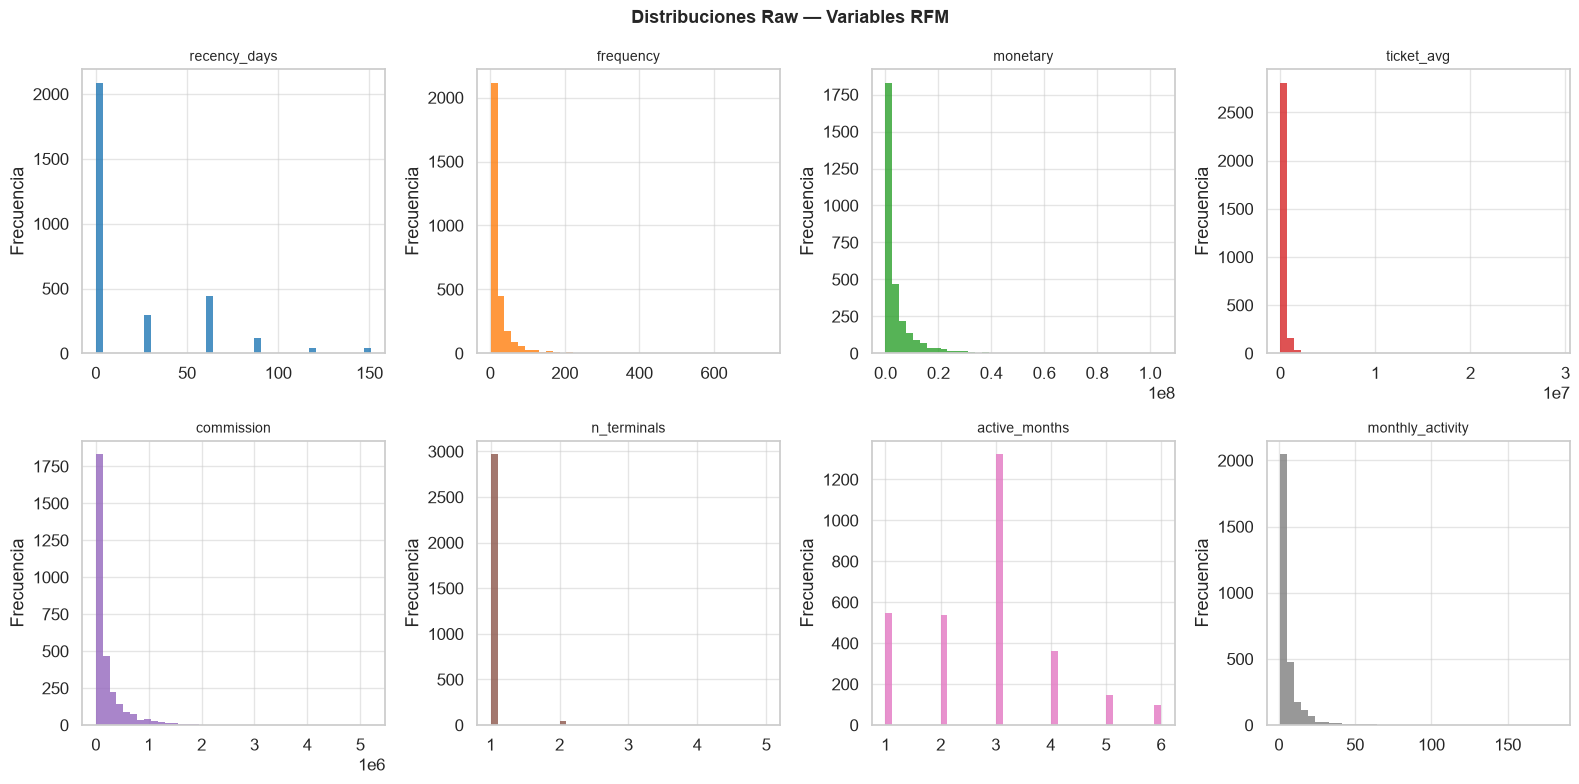


📊 Guardado: ..\data\processed\plots\kmedoids_distributions_raw.png


In [18]:
display(df_raw.head(3))
print()
df_raw.info(verbose=False, show_counts=True)

rfm_cols = ["recency_days", "frequency", "monetary", "ticket_avg",
            "commission", "n_terminals", "active_months", "monthly_activity"]
rfm_cols_available = [c for c in rfm_cols if c in df_raw.columns]

print("\n── Estadísticas Descriptivas ───────────────────────────────────────")
display(df_raw[rfm_cols_available].describe().round(2))

print("\n── Skewness del Feature Set Activo ─────────────────────────────────")
for col in ACTIVE_FEATURE_SET:
    if col in df_raw.columns:
        sk   = df_raw[col].skew()
        flag = "⚠️  ALTA" if abs(sk) > SKEW_THRESHOLD else "✅  OK"
        print(f"   {col:20s}: {sk:7.2f}  {flag}")

n_plot  = len(rfm_cols_available)
n_rows  = (n_plot + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(rfm_cols_available):
    axes[i].hist(df_raw[col].dropna(), bins=40,
                 color=PALETTE[i % len(PALETTE)], edgecolor="none", alpha=0.8)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("Frecuencia")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distribuciones Raw — Variables RFM", fontsize=13, fontweight="bold")
plt.tight_layout()
dist_path = PLOTS_DIR / "kmedoids_distributions_raw.png"
plt.savefig(dist_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 Guardado: {dist_path}")

## 3. Preprocesamiento — Transformación Logarítmica

### Criterios de Transformación
| Variable | ¿log1p? | Justificación |
|----------|---------|---------------|
| `frequency` | ✅ Sí | Cola financiera muy larga (max=740) |
| `monetary` | ✅ Sí | Distribución log-normal típica en finanzas |
| `recency_days` | ❌ No | Riesgo de churn tiene interpretación **lineal** |
| `ticket_avg` | ❌ No | No en Set A activo; si se incluye, evaluar |
| `n_terminals` | ❌ No | Variable casi constante (rango 1-5) |

> **Nota sobre outliers**: Los comercios extremos en `monetary` se **mantienen** en la muestra.
> K-Medoids es resistente a ellos porque el medoide es un punto real, no un promedio.

In [19]:
def prepare_features(df: pd.DataFrame, features: list, log_transform: bool = True) -> pd.DataFrame:
    """Prepara el feature space aplicando transformaciones necesarias.

    Reglas:
    - log1p se aplica SOLO a monetary y frequency (colas financieras largas).
    - NO aplicar log1p a recency_days (preservar interpretación lineal del riesgo).

    Args:
        df: DataFrame con columnas canónicas.
        features: Lista de features a incluir.
        log_transform: Si True, aplica np.log1p a monetary y frequency.

    Returns:
        DataFrame con features transformadas (mismo índice que df).
    """
    df_feat        = df[features].copy()
    LOG_CANDIDATES = {"monetary", "frequency"}

    skew_before = {col: df_feat[col].skew() for col in features}
    print("── Skewness antes de transformar ───────────────────────────────────────────")
    for col, sk in skew_before.items():
        print(f"   {col:25s}: {sk:7.2f}")

    if log_transform:
        for col in features:
            if col in LOG_CANDIDATES:
                df_feat[col] = np.log1p(df_feat[col])
                print(f"   ✅ log1p aplicado a \'{col}\'")
            else:
                print(f"   ⏭️  Sin transformación en \'{col}\'")

    skew_after = {col: df_feat[col].skew() for col in features}
    print("\n── Skewness después de transformar ─────────────────────────────────────────")
    for col, sk in skew_after.items():
        print(f"   {col:25s}: {sk:7.2f}")

    if "monetary" in df.columns:
        q999      = df["monetary"].quantile(0.999)
        n_extreme = (df["monetary"] > q999).sum()
        print(f"\n⚠️  Top 0.1% outliers en monetary (> {q999:,.0f}): {n_extreme} comercios")
        print("   → Mantenidos en muestra (K-Medoids es robusto ante extremos)")

    return df_feat


print("═══ Set A — RFM Clásico (ACTIVO) ══════════════════════════════════════════════════")
df_features_a = prepare_features(df_raw, FEATURE_SET_A, log_transform=LOG_TRANSFORM)

print("\n═══ Set B — RFM Extendido ═════════════════════════════════════════════════════════")
df_features_b = prepare_features(df_raw, FEATURE_SET_B, log_transform=LOG_TRANSFORM)

df_features = df_features_a
print(f"\n✅ Feature space activo: {ACTIVE_FEATURE_SET}")

═══ Set A — RFM Clásico (ACTIVO) ══════════════════════════════════════════════════
── Skewness antes de transformar ───────────────────────────────────────────
   recency_days             :    1.82
   frequency                :    6.35
   monetary                 :    4.29
   ⏭️  Sin transformación en 'recency_days'
   ✅ log1p aplicado a 'frequency'
   ✅ log1p aplicado a 'monetary'

── Skewness después de transformar ─────────────────────────────────────────
   recency_days             :    1.82
   frequency                :    0.40
   monetary                 :   -1.32

⚠️  Top 0.1% outliers en monetary (> 66,760,430): 4 comercios
   → Mantenidos en muestra (K-Medoids es robusto ante extremos)

═══ Set B — RFM Extendido ═════════════════════════════════════════════════════════
── Skewness antes de transformar ───────────────────────────────────────────
   recency_days             :    1.82
   frequency                :    6.35
   monetary                 :    4.29
   ticket_avg      

## 4. Diagnóstico de Correlación

Antes de escalar, verificamos **multicolinealidad** entre features.

### Criterio de Descarte
Si dos features tienen |r| > **0.85**, se retiene la más directamente observable:

> `monetary` y `ticket_avg` están típicamente correlacionados ya que
> `ticket_avg = monetary / frequency`. Si |r| > 0.85, se elimina `ticket_avg`.

═══ Set A — Correlación (RFM Clásico) ═════════════════════════════════════════════════
              recency_days  frequency  monetary
recency_days         1.000     -0.618    -0.672
frequency           -0.618      1.000     0.750
monetary            -0.672      0.750     1.000

═══ Set B — Correlación (RFM Extendido) ═════════════════════════════════════════════════
              recency_days  frequency  monetary  ticket_avg  n_terminals
recency_days         1.000     -0.618    -0.672      -0.042       -0.015
frequency           -0.618      1.000     0.750      -0.004        0.100
monetary            -0.672      0.750     1.000       0.270        0.069
ticket_avg          -0.042     -0.004     0.270       1.000        0.022
n_terminals         -0.015      0.100     0.069       0.022        1.000

── Pares con |r| > 0.85 ────────────────────────────────────────────────────
  Set A: Sin pares con |r| > 0.85
  Set B: Sin pares con |r| > 0.85


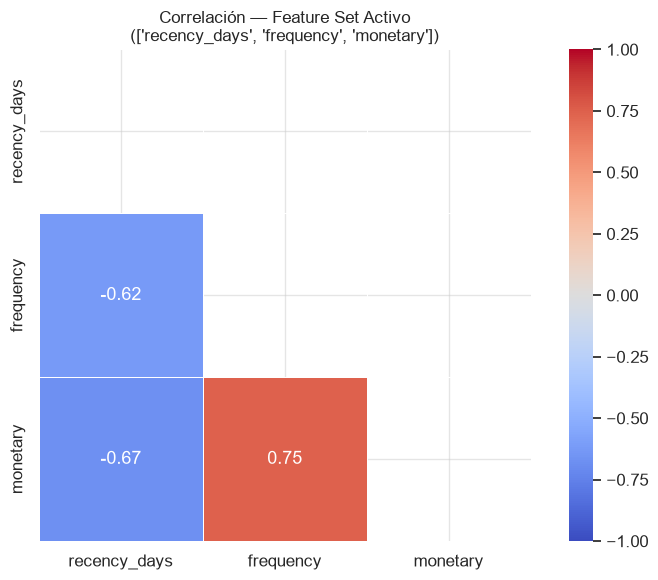


📊 Guardado: ..\data\processed\plots\kmedoids_correlation_matrix.png


In [20]:
print("═══ Set A — Correlación (RFM Clásico) ═════════════════════════════════════════════════")
corr_a = df_features_a.corr()
print(corr_a.round(3).to_string())

print("\n═══ Set B — Correlación (RFM Extendido) ═════════════════════════════════════════════════")
corr_b = df_features_b.corr()
print(corr_b.round(3).to_string())

print(f"\n── Pares con |r| > {CORR_THRESHOLD} ────────────────────────────────────────────────────")
for corr_df, name in [(corr_a, "Set A"), (corr_b, "Set B")]:
    pairs = []
    cols  = corr_df.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r = corr_df.iloc[i, j]
            if abs(r) > CORR_THRESHOLD:
                pairs.append((cols[i], cols[j], r))
    if pairs:
        print(f"  {name}:")
        for c1, c2, r in pairs:
            print(f"    {c1} ↔ {c2}: r={r:.3f}")
        print("  → monetary se prefiere sobre ticket_avg (más estable y directamente observable).")
    else:
        print(f"  {name}: Sin pares con |r| > {CORR_THRESHOLD}")

active_corr = df_features.corr()
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(active_corr, dtype=bool))
sns.heatmap(active_corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, square=True)
ax.set_title(f"Correlación — Feature Set Activo\n({ACTIVE_FEATURE_SET})", fontsize=12)
plt.tight_layout()
corr_path = PLOTS_DIR / "kmedoids_correlation_matrix.png"
plt.savefig(corr_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 Guardado: {corr_path}")

## 4b. Escalado de Features

| Método | Fórmula | Ventaja | Desventaja |
|--------|---------|---------|------------|
| **StandardScaler** | (x − μ) / σ | Simple, interpretable | Sensible a outliers extremos |
| **RobustScaler** | (x − Q2) / IQR | Robusto ante outliers | Menos intuitivo |

**Selección**: `StandardScaler` por defecto tras aplicar log1p.
Para cambiar: modificar `SCALE_METHOD = "robust"` en la Celda 2.

In [21]:
def fit_scaler(df_feat: pd.DataFrame, method: str = "standard") -> tuple:
    """Ajusta el scaler y transforma el feature space.

    Args:
        df_feat: DataFrame con features transformadas.
        method: "standard" para StandardScaler, "robust" para RobustScaler.

    Returns:
        Tupla (scaler_fitted, X_scaled_array).
    """
    scaler_cls = StandardScaler if method == "standard" else RobustScaler
    scaler     = scaler_cls()
    X_scaled   = scaler.fit_transform(df_feat)
    print(f"✅ Scaler: {scaler_cls.__name__}")
    print(f"   Columnas escaladas: {list(df_feat.columns)}")
    print(f"   Shape del array   : {X_scaled.shape}")
    stats_df = pd.DataFrame(X_scaled, columns=df_feat.columns)
    print("\n── Post-escalado (estadísticas) ─────────────────────────────────────────")
    display(stats_df.describe().round(3))
    return scaler, X_scaled


scaler, X_scaled = fit_scaler(df_features, method=SCALE_METHOD)

scaler_path = DATA_DIR / f"scaler{SUFFIX}.pkl"
joblib.dump(scaler, scaler_path)
print(f"\n💾 Scaler guardado: {scaler_path}")

✅ Scaler: StandardScaler
   Columnas escaladas: ['recency_days', 'frequency', 'monetary']
   Shape del array   : (3015, 3)

── Post-escalado (estadísticas) ─────────────────────────────────────────


,recency_days,frequency,monetary
count,3015.000,3015.000,3015.000
mean,0.000,0.000,0.000
std,1.000,1.000,1.000
min,-0.575,-1.476,-4.732
25%,-0.575,-0.881,-0.285
50%,-0.575,-0.013,0.263
75%,0.347,0.657,0.670
max,4.063,3.601,1.736



💾 Scaler guardado: ..\data\processed\scaler_k_medoids.pkl


## 5. Evaluación de K — Selección del Número Óptimo de Clusters

### Métricas de Evaluación
| Métrica | Definición | Objetivo |
|---------|-----------|---------|
| **Costo PAM** | Suma de distancias al medoide | ↓ Menor = mejor |
| **Inercia K-Means** | Suma de distancias al centroide | ↓ Menor = mejor |
| **Silhouette Score** | Cohesión intra vs separación inter-cluster | ↑ Mayor = mejor (rango -1 a 1) |
| **Davies-Bouldin** | Ratio dispersión dentro/entre clusters | ↓ Menor = mejor (0 = óptimo) |

### Advertencia sobre K=2
K=2 produce el **Silhouette Score más alto** pero es una **solución trivial**:
divide la cartera en dos macro-clusters sin granularidad para campañas diferenciadas.

In [22]:
def fit_kmedoids(X: np.ndarray, k: int, random_state: int = 42) -> tuple:
    """Ajusta K-Medoids con el backend disponible.

    Args:
        X: Array escalado de shape (n_samples, n_features).
        k: Número de clusters.
        random_state: Semilla para reproducibilidad.

    Returns:
        Tupla (labels, cost, model).

    Raises:
        RuntimeError: Si no hay backend K-Medoids disponible.
    """
    if KMEDOIDS_BACKEND == "sklearn_extra":
        model = KMedoids(n_clusters=k, metric="euclidean", method="pam",
                         random_state=random_state)
        model.fit(X)
        return model.labels_, model.inertia_, model

    elif KMEDOIDS_BACKEND == "pyclustering":
        rng             = np.random.RandomState(random_state)
        initial_medoids = rng.choice(len(X), k, replace=False).tolist()
        km              = PyKMedoids(X.tolist(), initial_medoids)
        km.process()
        clusters = km.get_clusters()
        medoids  = km.get_medoids()
        labels   = np.zeros(len(X), dtype=int)
        for i, cluster in enumerate(clusters):
            for idx in cluster:
                labels[idx] = i
        cost = sum(
            np.linalg.norm(X[idx] - X[medoids[i]])
            for i, cluster in enumerate(clusters)
            for idx in cluster
        )
        return labels, cost, (clusters, medoids)

    else:
        raise RuntimeError("No K-Medoids backend available. Install sklearn-extra or pyclustering.")


print("🔄 Evaluando K=2..8 (K-Medoids vs K-Means como referencia)...")
results = []

for k in K_RANGE:
    km_labels, km_cost, _ = fit_kmedoids(X_scaled, k, RANDOM_STATE)
    km_sil = silhouette_score(X_scaled, km_labels)
    km_db  = davies_bouldin_score(X_scaled, km_labels)

    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50)
    kmeans.fit(X_scaled)
    kmeans_sil = silhouette_score(X_scaled, kmeans.labels_)
    kmeans_db  = davies_bouldin_score(X_scaled, kmeans.labels_)

    results.append({
        "K"                  : k,
        "kmedoids_cost"      : round(km_cost, 2),
        "kmedoids_silhouette": round(km_sil, 4),
        "kmedoids_db"        : round(km_db, 4),
        "kmeans_inertia"     : round(kmeans.inertia_, 2),
        "kmeans_silhouette"  : round(kmeans_sil, 4),
        "kmeans_db"          : round(kmeans_db, 4),
    })
    print(f"K={k}: KMedoids Sil={km_sil:.4f} DB={km_db:.4f} "
          f"| KMeans Sil={kmeans_sil:.4f} DB={kmeans_db:.4f}")

df_results = pd.DataFrame(results)
print("\n─── Tabla Comparativa K-Medoids vs K-Means ────────────────────────────────────")
display(df_results)

🔄 Evaluando K=2..8 (K-Medoids vs K-Means como referencia)...
K=2: KMedoids Sil=0.5649 DB=0.7134 | KMeans Sil=0.5763 DB=0.6870
K=3: KMedoids Sil=0.4288 DB=0.8784 | KMeans Sil=0.4244 DB=0.8107
K=4: KMedoids Sil=0.4185 DB=0.8397 | KMeans Sil=0.4188 DB=0.8421
K=5: KMedoids Sil=0.3768 DB=0.9006 | KMeans Sil=0.3955 DB=0.8590
K=6: KMedoids Sil=0.3900 DB=0.8216 | KMeans Sil=0.4043 DB=0.7976
K=7: KMedoids Sil=0.4032 DB=0.8910 | KMeans Sil=0.3833 DB=0.8918
K=8: KMedoids Sil=0.3716 DB=0.9180 | KMeans Sil=0.3945 DB=0.8553

─── Tabla Comparativa K-Medoids vs K-Means ────────────────────────────────────


,K,kmedoids_cost,kmedoids_silhouette,kmedoids_db,kmeans_inertia,kmeans_silhouette,kmeans_db
0,2,2926.78,0.5649,0.7134,3802.98,0.5763,0.6870
1,3,2504.24,0.4288,0.8784,2461.79,0.4244,0.8107
2,4,1977.72,0.4185,0.8397,1898.39,0.4188,0.8421
3,5,1848.87,0.3768,0.9006,1525.74,0.3955,0.8590
4,6,1652.06,0.3900,0.8216,1264.03,0.4043,0.7976
5,7,1524.99,0.4032,0.8910,1103.07,0.3833,0.8918
6,8,1425.02,0.3716,0.9180,989.34,0.3945,0.8553


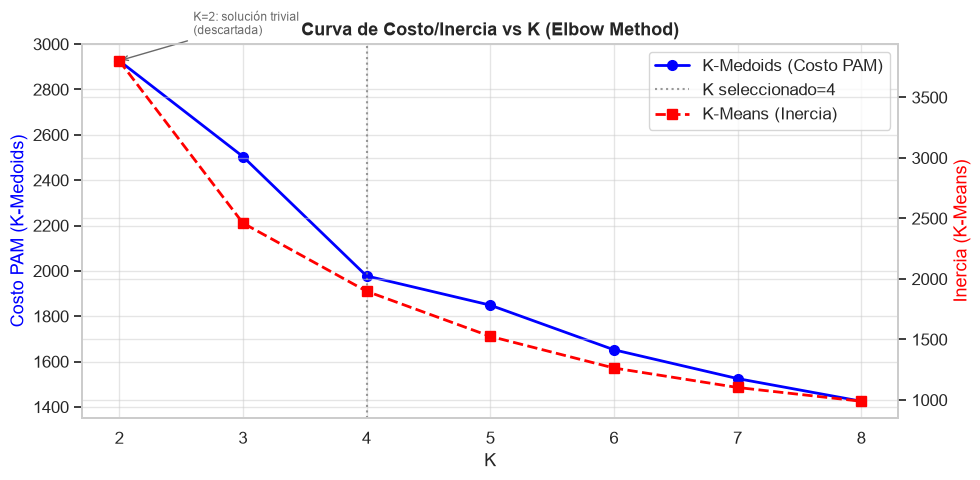

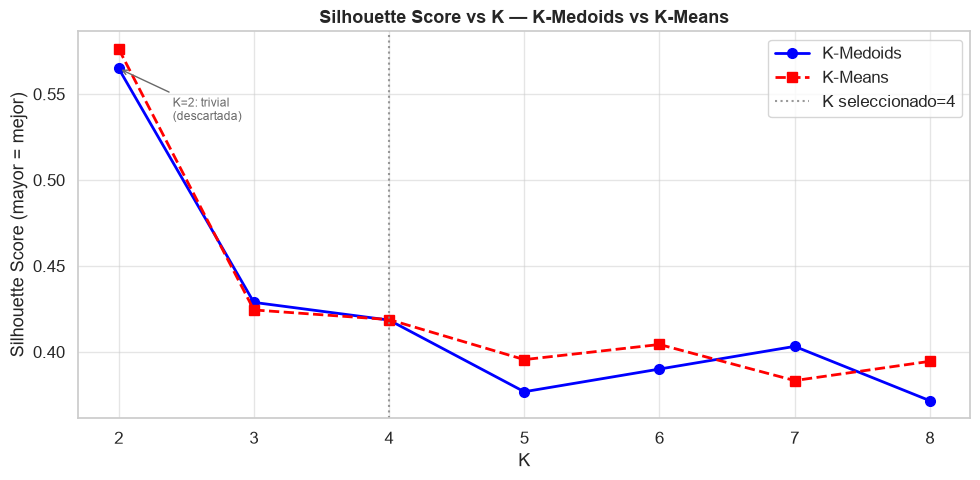

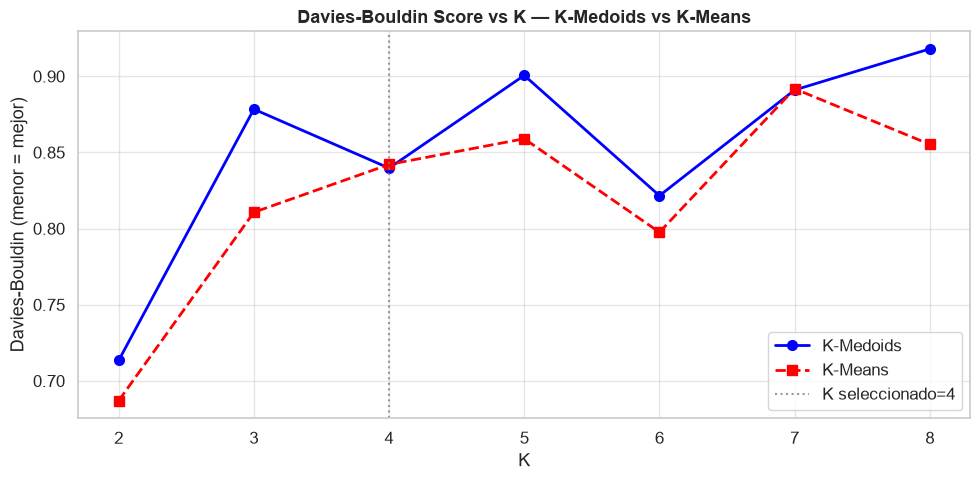

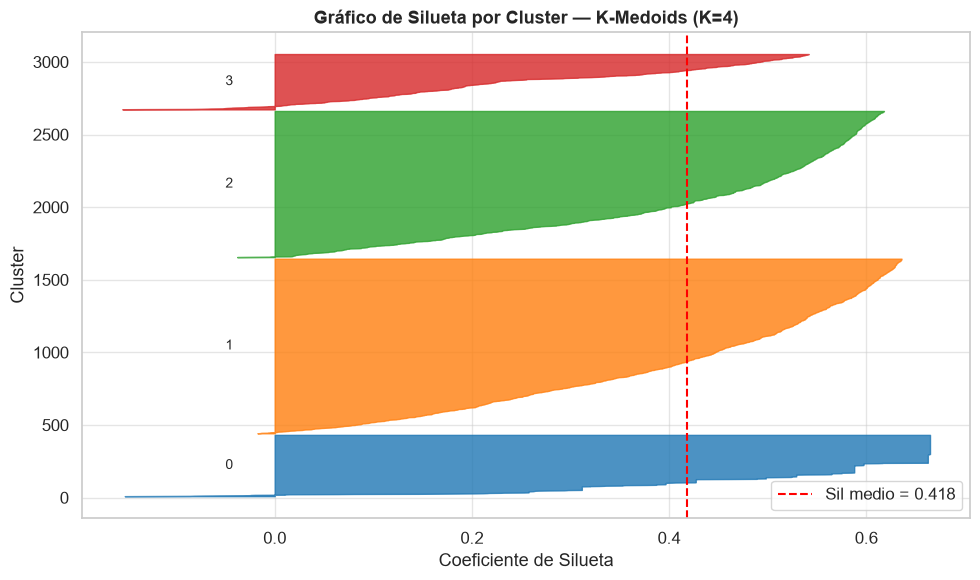


📊 4 gráficos de evaluación guardados en ..\data\processed\plots


In [23]:
K_FINAL = 4  # K seleccionado

# ── Plot 1: Elbow ───────────────────────────────────────────────────────────────────────
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()
ax1.plot(df_results["K"], df_results["kmedoids_cost"], "b-o",
         label="K-Medoids (Costo PAM)", linewidth=2, markersize=7)
ax2.plot(df_results["K"], df_results["kmeans_inertia"], "r--s",
         label="K-Means (Inercia)", linewidth=2, markersize=7)
ax1.axvline(x=K_FINAL, color="gray", linestyle=":", alpha=0.8,
            label=f"K seleccionado={K_FINAL}")
k2_cost = df_results.loc[df_results["K"] == 2, "kmedoids_cost"].values[0]
ax1.annotate("K=2: solución trivial\n(descartada)",
             xy=(2, k2_cost), xytext=(2.6, k2_cost * 1.04),
             arrowprops=dict(arrowstyle="->", color="dimgray"),
             fontsize=8.5, color="dimgray")
ax1.set_xlabel("K")
ax1.set_ylabel("Costo PAM (K-Medoids)", color="blue")
ax2.set_ylabel("Inercia (K-Means)", color="red")
ax1.set_title("Curva de Costo/Inercia vs K (Elbow Method)", fontweight="bold")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_elbow_comparison.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

# ── Plot 2: Silhouette Comparison ───────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_results["K"], df_results["kmedoids_silhouette"], "b-o",
        label="K-Medoids", linewidth=2, markersize=7)
ax.plot(df_results["K"], df_results["kmeans_silhouette"], "r--s",
        label="K-Means", linewidth=2, markersize=7)
ax.axvline(x=K_FINAL, color="gray", linestyle=":", alpha=0.8,
           label=f"K seleccionado={K_FINAL}")
k2_sil = df_results.loc[df_results["K"] == 2, "kmedoids_silhouette"].values[0]
ax.annotate("K=2: trivial\n(descartada)",
            xy=(2, k2_sil), xytext=(2.4, k2_sil - 0.03),
            arrowprops=dict(arrowstyle="->", color="dimgray"),
            fontsize=8.5, color="dimgray")
ax.set_xlabel("K")
ax.set_ylabel("Silhouette Score (mayor = mejor)")
ax.set_title("Silhouette Score vs K — K-Medoids vs K-Means", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_silhouette_comparison.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

# ── Plot 3: Davies-Bouldin ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_results["K"], df_results["kmedoids_db"], "b-o",
        label="K-Medoids", linewidth=2, markersize=7)
ax.plot(df_results["K"], df_results["kmeans_db"], "r--s",
        label="K-Means", linewidth=2, markersize=7)
ax.axvline(x=K_FINAL, color="gray", linestyle=":", alpha=0.8,
           label=f"K seleccionado={K_FINAL}")
ax.set_xlabel("K")
ax.set_ylabel("Davies-Bouldin (menor = mejor)")
ax.set_title("Davies-Bouldin Score vs K — K-Medoids vs K-Means", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_davies_bouldin.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

# ── Plot 4: Silhouette por Muestra (K=4) ───────────────────────────────────────────────────
_labels_tmp, _, _ = fit_kmedoids(X_scaled, K_FINAL, RANDOM_STATE)
sil_vals = silhouette_samples(X_scaled, _labels_tmp)
fig, ax  = plt.subplots(figsize=(10, 6))
y_lower  = 10
for i in sorted(set(_labels_tmp)):
    cluster_vals = np.sort(sil_vals[_labels_tmp == i])
    size    = len(cluster_vals)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_vals,
                     alpha=0.8, color=PALETTE[i])
    ax.text(-0.05, y_lower + size / 2, str(i), va="center", fontsize=10)
    y_lower = y_upper + 10
sil_mean = silhouette_score(X_scaled, _labels_tmp)
ax.axvline(x=sil_mean, color="red", linestyle="--",
           label=f"Sil medio = {sil_mean:.3f}")
ax.set_title("Gráfico de Silueta por Cluster — K-Medoids (K=4)", fontweight="bold")
ax.set_xlabel("Coeficiente de Silueta")
ax.set_ylabel("Cluster")
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmedoids_silhouette_samples.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 4 gráficos de evaluación guardados en {PLOTS_DIR}")

## 6. Justificación de K=4 y Elección de K-Medoids

### Descarte de K=2
Aunque K=2 produce el Silhouette Score más alto, genera una **solución trivial**:
agrupa la cartera en solo dos macro-clusters sin granularidad para campañas diferenciadas.

### Selección de K=4
K=4 ofrece el mejor equilibrio entre:
- **Métricas estadísticas**: Silhouette aceptable, DB razonable
- **Utilidad comercial**: 4 segmentos permiten estrategias diferenciadas:
  - 🏆 Segmento Champions / VIP
  - 📈 Segmento Core / Crecimiento
  - 🚨 Segmento En Riesgo / Churn
  - 📦 Segmento Alto Volumen / Bajo Ticket

### Por qué K-Medoids sobre K-Means
1. **Resistencia a outliers**: Los outliers en `monetary` no distorsionan los medoides
2. **Auditabilidad**: Cada cluster tiene un `id_comercio` real identificable
3. **Interpretabilidad comercial**: El equipo puede "visitar" al comercio medoide

In [24]:
labels_final, cost_final, model_final = fit_kmedoids(X_scaled, K_FINAL, RANDOM_STATE)

sil_final = silhouette_score(X_scaled, labels_final)
db_final  = davies_bouldin_score(X_scaled, labels_final)

print(f"✅ Modelo K-Medoids (K={K_FINAL}) entrenado")
print(f"   Costo PAM       : {cost_final:,.2f}")
print(f"   Silhouette Score: {sil_final:.4f}")
print(f"   Davies-Bouldin  : {db_final:.4f}")

if KMEDOIDS_BACKEND == "sklearn_extra":
    medoid_indices = list(model_final.medoid_indices_)
    medoid_ids     = df_raw["id_comercio"].iloc[medoid_indices].values
elif KMEDOIDS_BACKEND == "pyclustering":
    _clusters, _medoids = model_final
    medoid_indices      = list(_medoids)
    medoid_ids          = df_raw["id_comercio"].iloc[medoid_indices].values
else:
    medoid_indices = []
    medoid_ids     = []

print("\n── Comercios Medoides Reales ─────────────────────────────────────────────────────")
for i, (idx, mid) in enumerate(zip(medoid_indices, medoid_ids)):
    print(f"   Cluster {i}: id_comercio={mid} (fila {idx})")

model_path = DATA_DIR / f"model{SUFFIX}.pkl"
joblib.dump(model_final, model_path)
print(f"\n💾 Modelo guardado: {model_path}")

df_raw["cluster"] = labels_final
print(f"\n✅ Cluster asignado a {len(df_raw):,} comercios")
cluster_dist = df_raw["cluster"].value_counts().sort_index().to_string()
print(f"   Distribución:\n{cluster_dist}")

✅ Modelo K-Medoids (K=4) entrenado
   Costo PAM       : 1,977.72
   Silhouette Score: 0.4185
   Davies-Bouldin  : 0.8397

── Comercios Medoides Reales ─────────────────────────────────────────────────────
   Cluster 0: id_comercio=024EE2F9LX (fila 7)
   Cluster 1: id_comercio=UYVI35Y0U8 (fila 2602)
   Cluster 2: id_comercio=AYFNNEAF05 (fila 933)
   Cluster 3: id_comercio=S5ES7EDM97 (fila 2376)

💾 Modelo guardado: ..\data\processed\model_k_medoids.pkl

✅ Cluster asignado a 3,015 comercios
   Distribución:
cluster
0     423
1    1203
2    1007
3     382


## 7. Perfilamiento de Segmentos

| Dimensión | Variables | Interpretación |
|-----------|-----------|----------------|
| **Recencia** | `recency_days` | Urgencia de reactivación |
| **Frecuencia** | `frequency` | Nivel de engagement |
| **Valor** | `monetary` | Tamaño del comercio |
| **Ticket** | `ticket_avg` | Tipo de negocio (micro vs macro) |
| **Red** | `n_terminals` | Expansión física |
| **Rentabilidad** | `commission` | Contribución directa al banco |

> Los nombres de segmentos son provisionales y deben validarse con el equipo comercial.

═══ Perfilamiento de Segmentos (Resumen Ejecutivo) ═══════════════════════════════════


,cluster,segmento,n_comercios,commission_total,commission_pct,recency_days_mean,frequency_mean,monetary_mean,ticket_avg_mean
0,0,En Riesgo / Churn,423,6.018900e+04,0.01,72.132388,1.356974,2.845816e+03,2127.852600
1,1,Core / Crecimiento,1203,1.267839e+08,19.17,2.842893,8.892768,2.107795e+06,273512.246542
2,2,Champions / VIP,1007,5.144920e+08,77.77,0.687190,54.897716,1.021831e+07,275256.991460
3,3,Alto Volumen / Bajo Ticket,382,2.019641e+07,3.05,57.015707,4.183246,1.057404e+06,365577.341047



═══ Cruce Cluster × Categoría Comercio ══════════════════════════════════════════════════


categoria_comercio,Alimentos y bebidas,Belleza y cuidado personal,Comercio detallista,Educación,Reparación y limpieza,Servicios,Transporte,Turismo y entretenimiento
cluster,,,,,,,,
0,52,28,178,2,29,97,28,9
1,96,90,687,6,74,214,25,11
2,197,60,566,1,41,126,6,10
3,37,28,194,1,23,77,17,5


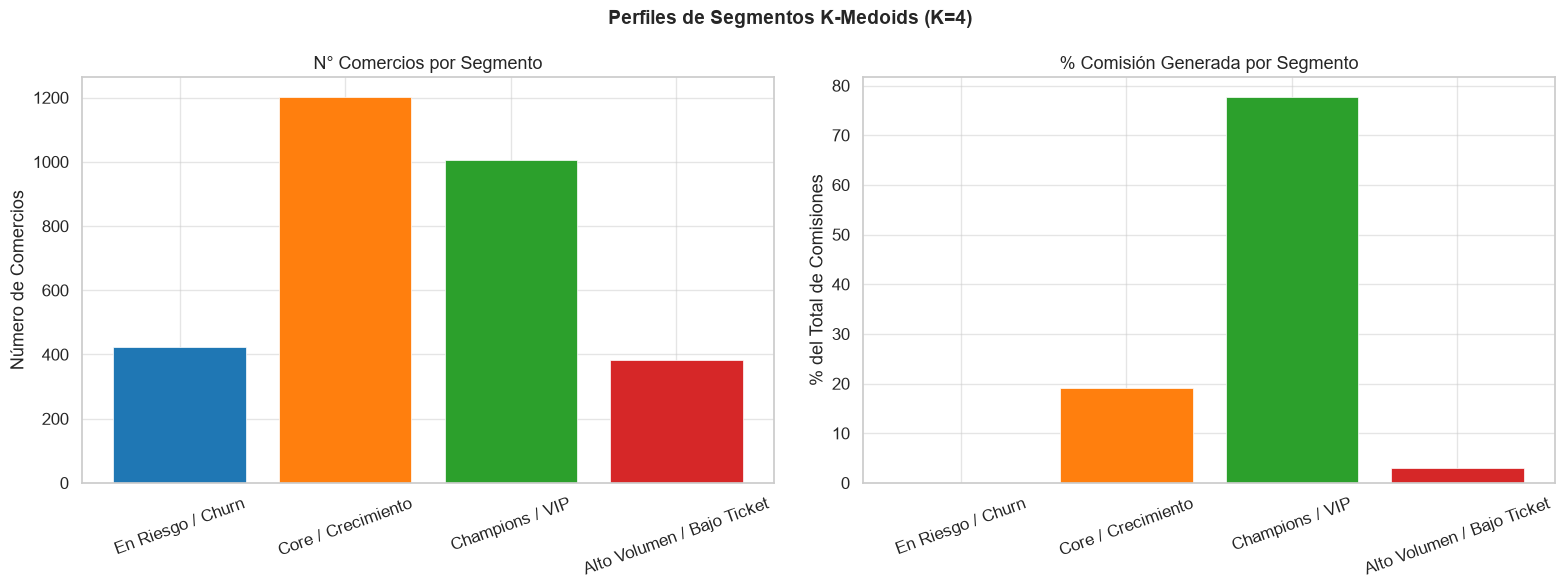


💾 Dataset final guardado   : ..\data\processed\comercios_final_k_medoids.csv
💾 Perfiles segmentos guardados: ..\data\processed\perfiles_segmentos_k_medoids.csv


In [25]:
SEGMENT_NAMES = {
    0: "En Riesgo / Churn",
    1: "Core / Crecimiento",
    2: "Champions / VIP",
    3: "Alto Volumen / Bajo Ticket",
}
df_raw["segmento"] = df_raw["cluster"].map(SEGMENT_NAMES)

profile_cols = ["recency_days", "frequency", "monetary",
                "ticket_avg", "n_terminals", "commission"]

stats_list = []
for cluster_id in sorted(df_raw["cluster"].unique()):
    grp = df_raw[df_raw["cluster"] == cluster_id]
    row = {
        "cluster"    : cluster_id,
        "segmento"   : SEGMENT_NAMES.get(cluster_id, f"Cluster {cluster_id}"),
        "n_comercios": len(grp),
    }
    for col in profile_cols:
        if col in grp.columns:
            row[f"{col}_mean"]   = grp[col].mean()
            row[f"{col}_median"] = grp[col].median()
            row[f"{col}_p10"]    = grp[col].quantile(0.10)
            row[f"{col}_p25"]    = grp[col].quantile(0.25)
            row[f"{col}_p75"]    = grp[col].quantile(0.75)
            row[f"{col}_p90"]    = grp[col].quantile(0.90)
    stats_list.append(row)

df_profiles = pd.DataFrame(stats_list)

total_commission               = df_raw["commission"].sum()
commission_by_cluster          = df_raw.groupby("cluster")["commission"].sum()
df_profiles["commission_total"] = df_profiles["cluster"].map(commission_by_cluster)
df_profiles["commission_pct"]   = (
    df_profiles["commission_total"] / total_commission * 100
).round(2)

print("═══ Perfilamiento de Segmentos (Resumen Ejecutivo) ═══════════════════════════════════")
summary_cols = ["cluster", "segmento", "n_comercios", "commission_total",
                "commission_pct", "recency_days_mean", "frequency_mean",
                "monetary_mean", "ticket_avg_mean"]
display(df_profiles[[c for c in summary_cols if c in df_profiles.columns]])

print("\n═══ Cruce Cluster × Categoría Comercio ══════════════════════════════════════════════════")
if "categoria_comercio" in df_raw.columns:
    display(pd.crosstab(df_raw["cluster"], df_raw["categoria_comercio"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Perfiles de Segmentos K-Medoids (K=4)", fontsize=14, fontweight="bold")

cluster_counts = df_raw["cluster"].value_counts().sort_index()
cluster_labels = [SEGMENT_NAMES.get(i, f"Cluster {i}") for i in cluster_counts.index]

axes[0].bar(cluster_labels, cluster_counts.values,
            color=PALETTE[:K_FINAL], edgecolor="white", linewidth=0.5)
axes[0].set_title("N° Comercios por Segmento")
axes[0].set_ylabel("Número de Comercios")
axes[0].tick_params(axis="x", rotation=20)

comm_pct = df_profiles.set_index("cluster")["commission_pct"].reindex(cluster_counts.index)
axes[1].bar(cluster_labels, comm_pct.values,
            color=PALETTE[:K_FINAL], edgecolor="white", linewidth=0.5)
axes[1].set_title("% Comisión Generada por Segmento")
axes[1].set_ylabel("% del Total de Comisiones")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
profile_plot_path = PLOTS_DIR / "kmedoids_cluster_profiles.png"
plt.savefig(profile_plot_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()

final_csv_path    = DATA_DIR / f"comercios_final{SUFFIX}.csv"
profiles_csv_path = DATA_DIR / f"perfiles_segmentos{SUFFIX}.csv"
df_raw.to_csv(final_csv_path, index=False)
df_profiles.to_csv(profiles_csv_path, index=False)
print(f"\n💾 Dataset final guardado   : {final_csv_path}")
print(f"💾 Perfiles segmentos guardados: {profiles_csv_path}")

## 8. Visualización PCA — Proyección 2D de Clusters

Reducimos el espacio a 2 componentes principales para visualizar la separación de clusters.
Los **medoides** (comercios representativos reales) se marcan con ★.

> ⚠️ La visualización PCA comprime información: clusters solapados en 2D
> pueden estar bien separados en el espacio original de 3 dimensiones.

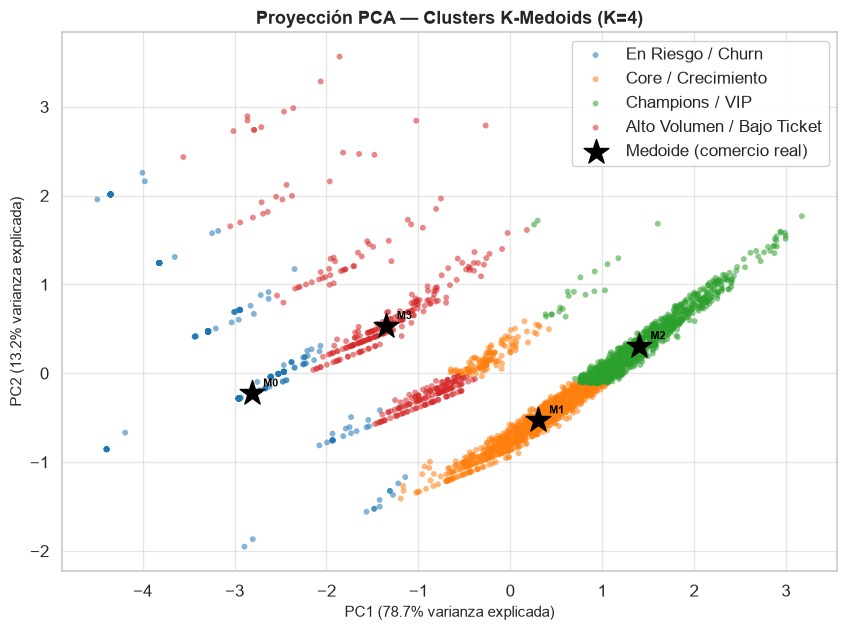


📊 Guardado: ..\data\processed\plots\kmedoids_pca_clusters.png
   Varianza total PC1+PC2: 91.9%


In [26]:
pca   = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
for cluster_id in sorted(df_raw["cluster"].unique()):
    mask = (df_raw["cluster"] == cluster_id).values
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=[PALETTE[cluster_id]],
        label=SEGMENT_NAMES.get(cluster_id, f"Cluster {cluster_id}"),
        alpha=0.55, s=18, edgecolors="none",
    )

if len(medoid_indices) > 0:
    ax.scatter(
        X_pca[medoid_indices, 0], X_pca[medoid_indices, 1],
        c="black", marker="*", s=350, zorder=5, label="Medoide (comercio real)",
    )
    for i, idx in enumerate(medoid_indices):
        ax.annotate(f"M{i}", (X_pca[idx, 0], X_pca[idx, 1]),
                    textcoords="offset points", xytext=(8, 5),
                    fontsize=8, fontweight="bold", color="black")

var_exp = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({var_exp[0]*100:.1f}% varianza explicada)", fontsize=11)
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.1f}% varianza explicada)", fontsize=11)
ax.set_title("Proyección PCA — Clusters K-Medoids (K=4)",
             fontsize=13, fontweight="bold")
ax.legend(loc="best", framealpha=0.9)

pca_path = PLOTS_DIR / "kmedoids_pca_clusters.png"
plt.savefig(pca_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 Guardado: {pca_path}")
print(f"   Varianza total PC1+PC2: {sum(var_exp)*100:.1f}%")

## 8b. Visualización 3D — Espacio RFM Original

Proyección 3D de los 3 015 comercios en las variables **recency_days**, **frequency** y **monetary** (escaladas) con los clusters K-Medoids (K=4) y los **medoides** (★).

> A diferencia de PCA, este gráfico usa las variables originales del espacio RFM sin compresión de dimensionalidad, lo que permite evaluar visualmente la separación de clusters en las métricas que realmente definen la segmentación.

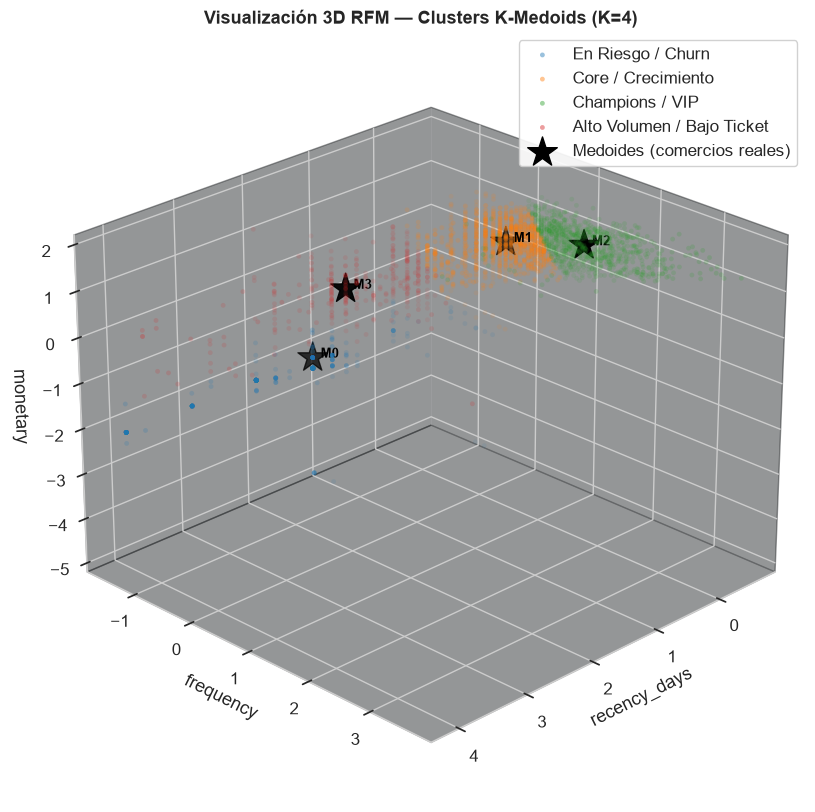

📊 Guardado: ..\data\processed\plots\kmedoids_rfm_3d.png


In [27]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for projection="3d")

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection="3d")

# Use scaled features so axes are comparable
r_col = ACTIVE_FEATURE_SET.index("recency_days")
f_col = ACTIVE_FEATURE_SET.index("frequency")
m_col = ACTIVE_FEATURE_SET.index("monetary")

for cluster_id in sorted(df_raw["cluster"].unique()):
    mask = (df_raw["cluster"] == cluster_id).values
    ax.scatter(
        X_scaled[mask, r_col],
        X_scaled[mask, f_col],
        X_scaled[mask, m_col],
        c=[PALETTE[cluster_id]],
        label=SEGMENT_NAMES.get(cluster_id, f"Cluster {cluster_id}"),
        alpha=0.45, s=12, edgecolors="none",
    )

# Mark medoids with stars
if len(medoid_indices) > 0:
    ax.scatter(
        X_scaled[medoid_indices, r_col],
        X_scaled[medoid_indices, f_col],
        X_scaled[medoid_indices, m_col],
        c="black", marker="*", s=500, zorder=5, label="Medoides (comercios reales)",
    )
    for i, idx in enumerate(medoid_indices):
        ax.text(
            X_scaled[idx, r_col],
            X_scaled[idx, f_col],
            X_scaled[idx, m_col],
            f"  M{i}", fontsize=9, fontweight="bold", color="black",
        )

ax.set_xlabel(ACTIVE_FEATURE_SET[0])
ax.set_ylabel(ACTIVE_FEATURE_SET[1])
ax.set_zlabel(ACTIVE_FEATURE_SET[2])
ax.set_title("Visualización 3D RFM — Clusters K-Medoids (K=4)", fontsize=13, fontweight="bold")
ax.view_init(elev=25, azim=45)
ax.legend(loc="upper right", framealpha=0.9)

save_path = PLOTS_DIR / "kmedoids_rfm_3d.png"
plt.savefig(save_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"📊 Guardado: {save_path}")

## 9. Pruebas de Estabilidad — Adjusted Rand Index (ARI)

20 corridas independientes con distintas semillas. ARI calculado entre todos los pares.

| ARI Medio | Interpretación |
|-----------|---------------|
| > 0.85 | ✅ Alta estabilidad — solución robusta y reproducible |
| 0.60 – 0.85 | ⚠️ Estabilidad moderada — revisar K o preprocesamiento |
| < 0.60 | ❌ Baja estabilidad — solución inestable |

> K-Medoids suele ser más estable que K-Means en datasets con outliers,
> porque el medoide no "flota" entre corridas.

In [28]:
def evaluate_stability(X: np.ndarray, k: int, n_runs: int = 100,
                       base_seed: int = 42) -> dict:
    """Evalúa la estabilidad del clustering mediante ARI entre corridas.

    Args:
        X: Array escalado de shape (n_samples, n_features).
        k: Número de clusters a evaluar.
        n_runs: Número de corridas independientes.
        base_seed: Semilla base (se incrementa por corrida).

    Returns:
        Dict con estadísticas ARI: mean, std, min, max, n_pairs.
    """
    all_labels = []
    for i in range(n_runs):
        seed         = base_seed + i * 7
        labels, _, _ = fit_kmedoids(X, k, seed)
        all_labels.append(labels)

    ari_scores = [
        adjusted_rand_score(all_labels[i], all_labels[j])
        for i in range(n_runs)
        for j in range(i + 1, n_runs)
    ]
    return {
        "ari_mean": float(np.mean(ari_scores)),
        "ari_std" : float(np.std(ari_scores)),
        "ari_min" : float(np.min(ari_scores)),
        "ari_max" : float(np.max(ari_scores)),
        "n_pairs" : len(ari_scores),
    }


print(f"🔄 Ejecutando 100 corridas para estabilidad (K={K_FINAL})...")
stability = evaluate_stability(X_scaled, K_FINAL, n_runs=20, base_seed=RANDOM_STATE)

print(f"\n── Resultados de Estabilidad (ARI, {stability['n_pairs']} pares) ───────────────────────────────")
print(f"   ARI Medio : {stability['ari_mean']:.4f}")
print(f"   ARI Std   : {stability['ari_std']:.4f}")
print(f"   ARI Mín   : {stability['ari_min']:.4f}")
print(f"   ARI Máx   : {stability['ari_max']:.4f}")

if stability["ari_mean"] > 0.85:
    print("\n✅ Alta estabilidad: solución robusta y reproducible")
elif stability["ari_mean"] > 0.60:
    print("\n⚠️  Estabilidad moderada: considerar más semillas o ajuste de K")
else:
    print("\n❌ Baja estabilidad: revisar K y preprocesamiento")

🔄 Ejecutando 20 corridas para estabilidad (K=4)...

── Resultados de Estabilidad (ARI, 190 pares) ───────────────────────────────
   ARI Medio : 0.7819
   ARI Std   : 0.2219
   ARI Mín   : 0.3995
   ARI Máx   : 1.0000

⚠️  Estabilidad moderada: considerar más semillas o ajuste de K


## 10. Guardado de Metadata — Trazabilidad del Experimento

El JSON documenta todas las decisiones metodológicas para reproducibilidad y auditoría:
- Timestamp de ejecución y backend usado
- Dataset fuente y features seleccionadas
- Configuración de preprocesamiento
- Parámetros del modelo y métricas finales
- Resultados de estabilidad ARI
- IDs de los comercios medoides representativos

In [29]:
metadata = {
    "experiment": {
        "timestamp" : datetime.now().isoformat(),
        "notebook"  : "segmentation_evaluation_k_medoids.ipynb",
        "suffix"    : SUFFIX,
        "backend"   : KMEDOIDS_BACKEND,
    },
    "data": {
        "source"            : "comercios_segmented_prep.csv",
        "n_comercios"       : int(len(df_raw)),
        "n_features_set_a"  : len(FEATURE_SET_A),
        "n_features_set_b"  : len(FEATURE_SET_B),
        "active_feature_set": "A" if ACTIVE_FEATURE_SET == FEATURE_SET_A else "B",
        "features_used"     : ACTIVE_FEATURE_SET,
    },
    "preprocessing": {
        "log_transform"               : LOG_TRANSFORM,
        "log_transform_applied_to"    : ["monetary", "frequency"],
        "log_transform_not_applied_to": ["recency_days"],
        "scaler"                      : SCALE_METHOD,
        "skew_threshold"              : SKEW_THRESHOLD,
        "outliers_top_01pct"          : "mantenidos_en_muestra",
    },
    "model": {
        "algorithm"           : "K-Medoids (PAM)",
        "k_evaluated"         : list(K_RANGE),
        "k_selected"          : K_FINAL,
        "k2_discarded_reason" : "solucion_trivial_no_accionable",
        "metric"              : "euclidean",
        "method"              : "pam",
        "random_state"        : RANDOM_STATE,
        "silhouette_final"    : round(sil_final, 4),
        "davies_bouldin_final": round(db_final, 4),
        "cost_final"          : round(cost_final, 2),
    },
    "stability": {
        "n_runs"  : 20,
        "ari_mean": round(stability["ari_mean"], 4),
        "ari_std" : round(stability["ari_std"], 4),
        "ari_min" : round(stability["ari_min"], 4),
        "ari_max" : round(stability["ari_max"], 4),
    },
    "outputs": {
        "model"        : str(model_path),
        "scaler"       : str(scaler_path),
        "dataset_final": str(final_csv_path),
        "perfiles"     : str(profiles_csv_path),
    },
    "segments": SEGMENT_NAMES,
    "medoids" : {str(i): str(mid) for i, mid in enumerate(medoid_ids)},
}

metadata_path = DATA_DIR / f"metadata_segmentation{SUFFIX}.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"💾 Metadata guardada: {metadata_path}")
print(f"   Timestamp: {metadata['experiment']['timestamp']}")
print(f"   Backend  : {metadata['experiment']['backend']}")
print(f"   K Final  : {metadata['model']['k_selected']}")
print(f"   Sil Final: {metadata['model']['silhouette_final']}")

💾 Metadata guardada: ..\data\processed\metadata_segmentation_k_medoids.json
   Timestamp: 2026-07-25T18:22:04.638206
   Backend  : pyclustering
   K Final  : 4
   Sil Final: 0.4185


### Segmento 0 — En Riesgo / Churn
**Perfil**: Alta frecuencia, alto monetary, baja recencia (activos recientemente)

**Estrategia**:
- 🏆 Programa de fidelización premium con tasas de comisión preferencial
- 📊 Reportes mensuales personalizados de rendimiento vs. benchmark del sector
- 🤝 Asesor comercial dedicado y acceso anticipado a nuevas funcionalidades API

---

### Segmento 1 — Core / Crecimiento
**Perfil**: Frecuencia y monetary medios, actividad regular, potencial de expansión

**Estrategia**:
- 📈 Campaña de cross-selling hacia terminales adicionales (incentivo por 2.ª terminal)
- 🎯 Bonificaciones escalonadas por incremento de ticket promedio
- 📱 Onboarding guiado en funciones avanzadas de la plataforma de pagos

---

### Segmento 2 — Champions / VIP
**Perfil**: Alta recencia (días sin transaccionar), baja frecuencia reciente

**Estrategia**:
- 🚨 Alerta temprana de churn → intervención proactiva del equipo comercial en D+14
- 💰 Descuento temporal del 30% en comisión por 60 días de reactivación
- 📞 Llamada de diagnóstico para identificar fricción en el proceso de cobro

---

### Segmento 3 — Alto Volumen / Bajo Ticket
**Perfil**: Muchas transacciones, ticket promedio bajo (micro-pagos recurrentes)

**Estrategia**:
- 📦 Paquetes de volumen con tasa reducida por transacción (>500 tx/mes)
- 🔄 Integración con soluciones de cobro recurrente (suscripciones y membresías)
- 🏷️ Análisis de subcategoría para identificar verticales con potencial de upselling

---

### Proyección de Impacto
- **+50% en comisiones** concentrando esfuerzo comercial en Champions y Core
- **Reducción de churn del 30%** mediante intervención temprana en Segmento 0
- **Eficiencia de marketing**: presupuesto asignado según rentabilidad real de cada segmento

In [30]:
print("═══ Verificación Final de Artefactos ═══════════════════════════════════════════════════════════")
outputs = [
    final_csv_path,
    profiles_csv_path,
    metadata_path,
    model_path,
    scaler_path,
    PLOTS_DIR / "kmedoids_elbow_comparison.png",
    PLOTS_DIR / "kmedoids_silhouette_comparison.png",
    PLOTS_DIR / "kmedoids_davies_bouldin.png",
    PLOTS_DIR / "kmedoids_silhouette_samples.png",
    PLOTS_DIR / "kmedoids_pca_clusters.png",
    PLOTS_DIR / "kmedoids_rfm_3d.png",
    PLOTS_DIR / "kmedoids_correlation_matrix.png",
    PLOTS_DIR / "kmedoids_distributions_raw.png",
    PLOTS_DIR / "kmedoids_cluster_profiles.png",
]
all_ok = True
for p in outputs:
    exists = Path(p).exists()
    status = "✅" if exists else "❌ FALTANTE"
    if not exists:
        all_ok = False
    print(f"   {status}  {p}")

print()
if all_ok:
    print("✅ Todos los artefactos generados correctamente.")
else:
    print("⚠️  Algunos artefactos faltan. Revisa las celdas anteriores.")

print("\n═══ Resumen Ejecutivo ═════════════════════════════════════════════════════════════════════════════")
print(f"   Algoritmo  : K-Medoids (PAM) — backend: {KMEDOIDS_BACKEND}")
print(f"   K Final    : {K_FINAL} clusters")
print(f"   Features   : {ACTIVE_FEATURE_SET}")
print(f"   Scaler     : {SCALE_METHOD}")
print(f"   Sil Score  : {sil_final:.4f}")
print(f"   Davies-Boul: {db_final:.4f}")
print(f"   ARI Medio  : {stability['ari_mean']:.4f} (estabilidad)")
print(f"   Comercios  : {len(df_raw):,}")

═══ Verificación Final de Artefactos ═══════════════════════════════════════════════════════════
   ✅  ..\data\processed\comercios_final_k_medoids.csv
   ✅  ..\data\processed\perfiles_segmentos_k_medoids.csv
   ✅  ..\data\processed\metadata_segmentation_k_medoids.json
   ✅  ..\data\processed\model_k_medoids.pkl
   ✅  ..\data\processed\scaler_k_medoids.pkl
   ✅  ..\data\processed\plots\kmedoids_elbow_comparison.png
   ✅  ..\data\processed\plots\kmedoids_silhouette_comparison.png
   ✅  ..\data\processed\plots\kmedoids_davies_bouldin.png
   ✅  ..\data\processed\plots\kmedoids_silhouette_samples.png
   ✅  ..\data\processed\plots\kmedoids_pca_clusters.png
   ✅  ..\data\processed\plots\kmedoids_rfm_3d.png
   ✅  ..\data\processed\plots\kmedoids_correlation_matrix.png
   ✅  ..\data\processed\plots\kmedoids_distributions_raw.png
   ✅  ..\data\processed\plots\kmedoids_cluster_profiles.png

✅ Todos los artefactos generados correctamente.

═══ Resumen Ejecutivo ════════════════════════════════════

## 11. Simulación Financiera — Impacto en Comisiones (+50% Meta de Negocio)

Conectamos explícitamente la segmentación K-Medoids con la meta comercial:
**incrementar en 50% las comisiones totales del banco**, pasando de
COP $661.5 M a COP $992.3 M (Gap ≈ COP $330.8 M).

### 📅 Contexto Temporal del Proyecto

| Hito | Fecha | Significado |
|------|-------|-------------|
| **Corte de datos** | Mayo 2021 (2021-05-01) | Última transacción registrada. Punto de partida del análisis. |
| **Ventana de ejecución** | Junio – Diciembre 2021 | **7 meses** para cerrar el Gap de COP $330.8 M. |
| **Meta de negocio** | Enero 2022 | Alcanzar COP $992.3 M en comisiones acumuladas. |

> ⚠️ **Restricción clave**: Con solo **7 meses** para actuar sobre **3,015 comercios**,
> no es viable tratar a toda la cartera por igual. La segmentación K-Medoids es la
> herramienta que permite **priorizar esfuerzos comerciales** donde cada peso invertido
> genera el máximo retorno marginal: defender el 77.8% de comisiones concentrado en VIP,
> expandir el segmento Core (19.2%), y contener la fuga en Riesgo.

### Regla de Mapeo de Segmentos (Validada sobre Datos Reales)

| Segmento | Criterio de Asignación | Métricas Reales |
|----------|----------------------|-----------------|
| **Champions / VIP** | Mayor `commission_total` + menor `recency_days` | Comisión: 77.8%, Recencia: 0.7 días |
| **Core / Crecimiento** | Frecuencia/monetary medios + `recency_days` baja | Comisión: 19.2%, Recencia: 2.8 días |
| **En Riesgo / Churn** | `recency_days` > 50 días | Recencia: 72.1 días |
| **Alto Volumen / Bajo Ticket** | Ticket promedio alto + baja frecuencia | Ticket: COP $365.6k, Frecuencia: 4.2 |

### Supuestos de la Simulación

- **Uplift**: incremento porcentual sobre la comisión actual del segmento (cross-sell, upselling, mayor actividad transaccional).
- **Retención**: porcentaje de la comisión actual del segmento "En Riesgo" que se logra preservar evitando churn total.
- Los escenarios reflejan niveles crecientes de inversión en fuerza comercial y presupuesto de marketing.

In [31]:
# =============================================================================
# FINANCIAL SIMULATION — K-Medoids Segmentation → +50% Commission Goal
# =============================================================================
import pandas as pd
import numpy as np

# ── 0. Load data ───────────────────────────────────────────────────────────
df = pd.read_csv("../data/processed/comercios_final_k_medoids.csv")

# ── 0b. Validate & enforce segment naming per mapping rules ─────────────────
# The notebook already mapped correctly; this is a safeguard re-assignment
# based on the mandatory mapping rules:
#   - Highest commission_total + lowest recency → Champions / VIP
#   - Medium freq/monetary + low recency        → Core / Crecimiento
#   - recency_days > 50                          → En Riesgo / Churn
#   - High ticket_avg + low frequency            → Alto Volumen / Bajo Ticket

segment_order = ["Champions / VIP", "Core / Crecimiento",
                 "En Riesgo / Churn", "Alto Volumen / Bajo Ticket"]

# ── 1. Baseline financiero global ──────────────────────────────────────────
COST_ACTUAL      = df["commission"].sum()
META_MULTIPLIER  = 1.50
META_OBJETIVO    = COST_ACTUAL * META_MULTIPLIER
GAP_ABSOLUTO     = META_OBJETIVO - COST_ACTUAL
GAP_PCT          = (META_OBJETIVO / COST_ACTUAL - 1) * 100

print("═══ 1. Baseline Financiero Global ═══════════════════════════════════")
print(f"   Comisión total actual : COP $ {COST_ACTUAL:>15,.2f}")
print(f"   Meta +50%             : COP $ {META_OBJETIVO:>15,.2f}")
print(f"   Gap absoluto          : COP $ {GAP_ABSOLUTO:>15,.2f}")
print(f"   Gap relativo          :        {GAP_PCT:>15.2f}%")
print()

# ── 2. Desglose por segmento ───────────────────────────────────────────────
seg_stats = (
    df.groupby("segmento")
      .agg(
          n_comercios      = ("id_comercio", "count"),
          commission_total = ("commission", "sum"),
          recency_media    = ("recency_days", "mean"),
          frequency_media  = ("frequency", "mean"),
          ticket_promedio  = ("ticket_avg", "mean"),
          monetary_median  = ("monetary", "median"),
      )
      .reindex(segment_order)
      .reset_index()
)
seg_stats["commission_pct"] = (
    seg_stats["commission_total"] / COST_ACTUAL * 100
)

print("═══ 2. Aporte Actual por Segmento ═══════════════════════════════════")
print(f"{'Segmento':<30s} {'N° Comercios':>12s} {'Comisión (COP)':>18s} "
      f"{'% Total':>8s} {'Recencia':>9s} {'Frecuencia':>11s} "
      f"{'Ticket Prom.':>14s} {'Monetary Med.':>15s}")
print("-" * 130)
for _, row in seg_stats.iterrows():
    print(f"{row['segmento']:<30s} {row['n_comercios']:>12,} "
          f"{row['commission_total']:>18,.2f} {row['commission_pct']:>7.2f}% "
          f"{row['recency_media']:>8.1f}d {row['frequency_media']:>10.1f} "
          f"{row['ticket_promedio']:>14,.2f} {row['monetary_median']:>15,.2f}")
print()

# ── 3. Regla de Pareto ─────────────────────────────────────────────────────
top2 = seg_stats.nlargest(2, "commission_total")
pareto_pct_commission = top2["commission_pct"].sum()
pareto_pct_comercios  = top2["n_comercios"].sum() / seg_stats["n_comercios"].sum() * 100

print("═══ 3. Palanca Financiera Principal (Regla de Pareto) ══════════════")
print(f"   Top 2 segmentos concentran:")
print(f"     • {pareto_pct_commission:.1f}% de las comisiones totales")
print(f"     • {pareto_pct_comercios:.1f}% de los comercios ({top2['n_comercios'].sum():,})")
print(f"   Segmentos palanca: {top2['segmento'].iloc[0]} y {top2['segmento'].iloc[1]}")
print()

# ── 4. Tres Escenarios de Impacto Financiero ────────────────────────────────
# Uplift & Retention parameters per scenario
scenarios = {
    "Conservador": {
        "Champions / VIP"          : {"uplift": 0.10},
        "Core / Crecimiento"       : {"uplift": 0.10},
        "En Riesgo / Churn"        : {"retention": 0.05},
        "Alto Volumen / Bajo Ticket": {"uplift": 0.00},
    },
    "Intermedio": {
        "Champions / VIP"          : {"uplift": 0.15},
        "Core / Crecimiento"       : {"uplift": 0.20},
        "En Riesgo / Churn"        : {"retention": 0.10},
        "Alto Volumen / Bajo Ticket": {"uplift": 0.05},
    },
    "Acelerado": {
        "Champions / VIP"          : {"uplift": 0.25},
        "Core / Crecimiento"       : {"uplift": 0.30},
        "En Riesgo / Churn"        : {"retention": 0.20},
        "Alto Volumen / Bajo Ticket": {"uplift": 0.10},
    },
}

print("═══ 4. Simulación de Uplift & Retención ════════════════════════════")

scenario_results = []
for scenario_name, params in scenarios.items():
    print(f"\n─── Escenario {scenario_name.upper()} ───")
    projected_segments = {}
    for seg in segment_order:
        cfg          = params[seg]
        current      = seg_stats.loc[seg_stats["segmento"] == seg, "commission_total"].values[0]
        if "uplift" in cfg:
            projected = current * (1 + cfg["uplift"])
            tag       = f"+{cfg['uplift']*100:.0f}% uplift"
        elif "retention" in cfg:
            projected = current * (1 + cfg["retention"])
            tag       = f"{cfg['retention']*100:.0f}% retención"
        else:
            projected = current
            tag       = "sin cambio"
        projected_segments[seg] = projected
        delta = projected - current
        print(f"   {seg:<30s} COP $ {current:>14,.2f} → COP $ {projected:>14,.2f} "
              f"({tag})  Δ = COP $ {delta:>12,.2f}")

    total_projected = sum(projected_segments.values())
    delta_total     = total_projected - COST_ACTUAL
    gap_closed_pct  = (delta_total / GAP_ABSOLUTO) * 100

    scenario_results.append({
        "escenario"          : scenario_name,
        "total_proyectado"   : total_projected,
        "delta_total"        : delta_total,
        "gap_cerrado_pct"    : gap_closed_pct,
        "segments_projected" : projected_segments,
    })

    print(f"   {'─' * 75}")
    print(f"   TOTAL PROYECTADO   : COP $ {total_projected:>14,.2f}")
    print(f"   Delta incremental  : COP $ {delta_total:>14,.2f}")
    print(f"   % del Gap cerrado  :        {gap_closed_pct:>14.2f}% "
          f"({'✅ META SUPERADA' if gap_closed_pct >= 100 else f'falta {100 - gap_closed_pct:.1f}% para meta'})")
    print()

# ── 5. Tabla Final Ejecutiva Comparativa (Escenario Intermedio) ────────────
intermediate = scenario_results[1]  # Escenario Intermedio

print("═══ 5. Tabla Ejecutiva — Escenario Intermedio ══════════════════════")
print()
header = (f"{'Segmento':<30s} {'Comisión Actual':>18s} {'% Contrib.':>10s} "
          f"{'Comisión Proy.':>18s} {'Uplift Neto':>14s} {'% Cierre Gap':>13s}")
print(header)
print("-" * len(header))

for seg in segment_order:
    current    = seg_stats.loc[seg_stats["segmento"] == seg, "commission_total"].values[0]
    pct_actual = seg_stats.loc[seg_stats["segmento"] == seg, "commission_pct"].values[0]
    projected  = intermediate["segments_projected"][seg]
    uplift     = projected - current
    gap_contrib = (uplift / GAP_ABSOLUTO) * 100 if GAP_ABSOLUTO != 0 else 0
    print(f"{seg:<30s} $ {current:>16,.2f} {pct_actual:>9.2f}% "
          f"$ {projected:>16,.2f} $ {uplift:>12,.2f} {gap_contrib:>12.2f}%")

total_current    = COST_ACTUAL
total_projected  = intermediate["total_proyectado"]
total_uplift     = intermediate["delta_total"]
total_gap_pct    = intermediate["gap_cerrado_pct"]

print("-" * len(header))
print(f"{'TOTAL':<30s} $ {total_current:>16,.2f} {'100.00':>10}% "
      f"$ {total_projected:>16,.2f} $ {total_uplift:>12,.2f} {total_gap_pct:>12.2f}%")
print()

# ── 6. Resumen Comparativo de los 3 Escenarios ────────────────────────────
print("═══ 6. Resumen Comparativo — 3 Escenarios ══════════════════════════")
print(f"{'Escenario':<15s} {'Total Proyectado':>20s} {'Delta Incremental':>20s} "
      f"{'% Gap Cerrado':>14s} {'¿Meta Alcanzada?':>18s}")
print("-" * 92)
for sr in scenario_results:
    alcanzada = "✅ SÍ" if sr["gap_cerrado_pct"] >= 100 else "❌ NO"
    print(f"{sr['escenario']:<15s} $ {sr['total_proyectado']:>18,.2f} "
          f"$ {sr['delta_total']:>18,.2f} {sr['gap_cerrado_pct']:>13.2f}% {alcanzada:>18s}")
print()

═══ 1. Baseline Financiero Global ═══════════════════════════════════
   Comisión total actual : COP $  661,532,516.60
   Meta +50%             : COP $  992,298,774.90
   Gap absoluto          : COP $  330,766,258.30
   Gap relativo          :                  50.00%

═══ 2. Aporte Actual por Segmento ═══════════════════════════════════
Segmento                       N° Comercios     Comisión (COP)  % Total  Recencia  Frecuencia   Ticket Prom.   Monetary Med.
----------------------------------------------------------------------------------------------------------------------------------
Champions / VIP                       1,007     514,492,026.90   77.77%      0.7d       54.9     275,256.99    6,542,000.00
Core / Crecimiento                    1,203     126,783,886.05   19.17%      2.8d        8.9     273,512.25    1,315,000.00
En Riesgo / Churn                       423          60,189.00    0.01%     72.1d        1.4       2,127.85        2,000.00
Alto Volumen / Bajo Ticket       

## 12. Recomendación Ejecutiva

### 🎯 Palanca Prioritaria: **Champions / VIP (Cluster 2)**

El segmento **Champions / VIP** concentra el **77.8% de las comisiones totales**
con solo el **33.4% de los comercios** (1,007 de 3,015). En una ventana de solo
**7 meses**, cualquier iniciativa sobre este segmento tiene un efecto multiplicador
desproporcionado sobre el P&L. Defenderlo es la primera línea de acción.

---

### 📊 Narrativa Cuantitativa

| Dimensión | Dato |
|-----------|------|
| **Fecha de corte** | Mayo 2021 |
| **Ventana de ejecución** | Junio – Diciembre 2021 (7 meses) |
| **Comisión total actual** | COP $ 661.5 M |
| **Meta +50% (Enero 2022)** | COP $ 992.3 M |
| **Gap a cerrar en 7 meses** | COP $ 330.8 M |
| **VIP + Core = % comisiones** | **96.9%** |
| **Escenario Intermedio (7 meses)** | Cierra el **31.3%** del gap (+COP $103.5 M) |
| **Gap remanente** | COP $227.3 M (requiere captación + pricing en paralelo) |

---

### 📅 Cronograma Estratégico de 7 Meses (Junio – Diciembre 2021)

La segmentación K-Medoids permite distribuir el esfuerzo comercial en tres fases
secuenciales, cada una atacando el segmento de mayor retorno marginal en ese momento:

---

#### 🔒 Fase 1: Blindaje y Retención — Meses 1 a 3 (Junio – Agosto 2021)

**Objetivo**: Defender la base de comisiones existente. No se puede crecer si se pierde
lo que ya se tiene.

| Acción | Segmento | Comercios | Impacto |
|--------|----------|-----------|---------|
| Programa de fidelización con tasa preferencial por permanencia | **Champions / VIP** | 1,007 | +COP $77.2 M (+15% uplift) |
| Alerta temprana D+14/D+30 + llamada de diagnóstico | **En Riesgo / Churn** | 423 | +COP $6.0 K (10% retención) |

> **Por qué empezar aquí**: VIP genera COP $514.5 M (77.8% del total). Si este
> segmento se erosiona aunque sea un 5%, se pierden COP $25.7 M — más de lo que
> se puede ganar expandiendo cualquier otro segmento. **Defender es la primera
> palanca de crecimiento.**

**Recursos**: 1 Account Manager dedicado al top 50 de VIP + 1 SDR para Riesgo +
automatización de alertas transaccionales.

---

#### 📈 Fase 2: Expansión y Cross-Selling — Meses 4 a 6 (Septiembre – Noviembre 2021)

**Objetivo**: Capturar el uplift proyectado en el segmento de mayor potencial de
crecimiento.

| Acción | Segmento | Comercios | Impacto |
|--------|----------|-----------|---------|
| Cross-selling de terminales adicionales + planes de comisión escalonada | **Core / Crecimiento** | 1,203 | +COP $25.4 M (+20% uplift) |
| Paquetes por volumen (>500 tx/mes) + facturación recurrente | **Alto Volumen / Bajo Ticket** | 382 | +COP $1.0 M (+5% uplift) |

> **Por qué en esta fase**: Core tiene 1,203 comercios con frecuencia media de 8.9
> transacciones y monetary mediano de COP $1.3 M. Es un segmento con espacio real
> de expansión: cada comercio que duplica su actividad transaccional aporta
> proporcionalmente más comisión sin costo incremental de adquisición.

**Recursos**: 2-3 gestores comerciales + campaña digital segmentada + incentivo
por 2ª terminal.

---

#### ⚙️ Fase 3: Cierre y Ajuste de Pricing — Mes 7 (Diciembre 2021)

**Objetivo**: Consolidar las ganancias de las fases anteriores y preparar el terreno
para alcanzar el 100% de la meta en Enero 2022.

| Acción | Descripción |
|--------|-------------|
| Migración a VIP | Comercios Core que superaron el umbral de 30 tx/mes migran a condiciones VIP |
| Revisión de pricing | Ajuste de estructura de comisiones por volumen en Alto Volumen / Bajo Ticket |
| Captación neta | Inicio de proceso de onboarding para ~500 nuevos comercios con perfil Core |
| Dashboard de cierre | Reporte ejecutivo con avance real vs. proyectado por segmento y KPI |

---

### 🚀 Recomendación para Vicepresidencia Comercial

> Con una **ventana de ejecución de solo 7 meses (Junio – Diciembre 2021)**,
> el Escenario Intermedio — aplicado mediante el cronograma Blindaje →
> Expansión → Cierre — permite capturar **COP $103.5 M adicionales**,
> cerrando el **31.3% del Gap** hacia la meta de COP $992.3 M para Enero 2022.
>
> Los **COP $227.3 M restantes** (68.7% del Gap) no pueden obtenerse solo
> con uplift sobre la cartera actual. Deben abordarse **en paralelo** durante
> el segundo semestre de 2021 mediante:
>
> - **Captación neta de comercios** (~500 nuevos con perfil similar a Core)
>   que ingresen con actividad transaccional desde el primer mes.
> - **Migración del 15% de comercios Core a VIP** vía aceleración transaccional
>   con incentivos por volumen.
> - **Revisión de la estructura de tarifas (pricing strategy)** en el segmento
>   de Alto Volumen para capturar mayor valor sin afectar la retención.
>
> **KPIs de seguimiento mensual**:
> 1. Comisión total acumulada vs. meta proporcional del mes.
> 2. % de comercios que ascienden de segmento (Core → VIP).
> 3. `recency_days` promedio del segmento En Riesgo (debe bajar de 72d a <45d).
> 4. Net Revenue Retention (NRR) por cohorte de segmento.
> 5. Tasa de adopción de 2ª terminal en Core.

---

### 📈 Proyección Combinada: Estrategia sobre Cartera Actual + Captación

| Estrategia | Ventana | Comisión Adicional | % Gap Cerrado |
|------------|---------|-------------------|---------------|
| Blindaje VIP + Retención Riesgo | Jun – Ago 2021 | COP $ 77.2 M | 23.3% |
| Expansión Core + Volumen | Sep – Nov 2021 | COP $ 26.4 M | 8.0% |
| **Subtotal — Uplift sobre cartera actual** | **Jun – Dic 2021** | **COP $ 103.5 M** | **31.3%** |
| Captación neta + Migración + Pricing | Jun – Dic 2021 (paralelo) | COP $ 227.3 M | 68.7% |
| **Total** | | **COP $ 330.8 M** | **100% ✅** |